# Three-Class Tweet Sentiment Classification Using Word and Character TF-IDF

**Dattu Nayak Paltya · I26043443**  
**PRG4206 Machine Learning · INTI International University, Malaysia**

## Abstract

This project evaluates classical machine-learning methods for assigning English tweets to negative, neutral, or positive sentiment categories. The experiment uses the official training, validation, and test partitions of TweetEval's sentiment task, representing 59,899 examples. Word and character TF-IDF features are evaluated with Multinomial Naive Bayes, Logistic Regression, and Linear Support Vector Machine (SVM), alongside a majority-class baseline. Stratified three-fold cross-validation selects each model's hyperparameters by macro-F1; validation macro-F1 selects the model family; the test partition provides the final evaluation. Linear SVM is selected with validation macro-F1 of 0.6765 and obtains 61.91% test accuracy and 0.6143 test macro-F1. Logistic Regression scores slightly higher on the test partition but is not substituted after test inspection. The implemented system includes data integrity checks, feature-level inspection, saved evaluation artifacts, and a local interactive dashboard. The results show that classical n-gram models capture useful benchmark signal, but their error rate and the test-set distribution shift make the predictions unsuitable as unreviewed judgments about individual posts.

## 1. Introduction and project objectives

Short social-media messages are difficult to classify because they can contain informal spelling, abbreviations, hashtags, emoticons, negation, mixed opinions, and sarcasm. A compact sentiment classifier can help organize a large collection of public feedback for exploratory review, but a single categorical prediction cannot capture every nuance of a message. This project studies the bounded machine-learning task of reproducing the three sentiment labels in the TweetEval benchmark.

The input is tweet text and the target is one of three benchmark classes: negative, neutral, or positive. The model does not use author identity, infer personal traits, identify the target of an opinion, measure sentiment intensity, or make moderation decisions. Its output is a prediction of an annotation label, not a claim about a writer's private emotional state.

The project objectives are to document the public dataset and its provenance; describe its partitions, labels, and class distributions; check data integrity; create word- and character-level text features without cross-validation leakage; compare a majority baseline with three classical learners; tune configurations using stratified cross-validation; select a model family by validation macro-F1; report held-out test performance and class-specific errors; and demonstrate the fitted pipeline through a local dashboard. The primary selection score is macro-F1 because it weights the three classes equally. Accuracy is also reported because it is a familiar measure of total correct predictions.

## 2. Dataset collection and provenance

The dataset is the public `sentiment` configuration of [TweetEval](https://huggingface.co/datasets/cardiffnlp/tweet_eval), obtained using Hugging Face `datasets`. TweetEval is a unified benchmark for tweet classification with fixed train, validation, and test partitions. The original benchmark paper is Barbieri et al. (2020), “TweetEval: Unified Benchmark and Comparative Evaluation for Tweet Classification” [1]. The target labels follow the dataset mapping: 0 is negative, 1 is neutral, and 2 is positive [2]. The dataset contains text and label fields; author identities, engagement statistics, timestamps, and user-profile information are not model inputs.

The sentiment task originates from SemEval-2017 Task 4A and earlier source material [1], [3]. TweetEval's benchmark release was published in 2020, but the underlying posts were collected earlier. The benchmark publication date and source-post dates are therefore distinct. The course's interpretation of its recency requirement should account for that distinction. The dataset card identifies license information as unknown, and the official repository cautions that source-component and platform terms may apply [2], [4]. The project does not claim unrestricted redistribution rights.

Prior work establishes the benchmark's research context. Loureiro et al. (2022) describe Twitter language models and report TweetEval evaluations [5]; Barbieri et al. (2022) introduce multilingual Twitter models evaluated within the TweetEval framework [6]; and Huang and Usbeck (2024) study supervised contrastive learning for microblog classification using TweetEval tasks [10]. The exact split and scoring equivalence of every later study is not assumed. Their use of the benchmark provides literature context, while direct numerical comparisons require matching evaluation protocols.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.model import (
    ARTIFACTS,
    DATA_DIR,
    LABELS,
    _metrics,
    _write_confusion_matrix,
    _write_eda,
    bootstrap_macro_f1_differences,
    build_model_searches,
    export_dataset_csvs,
    load_splits,
    predict,
)

ARTIFACTS.mkdir(parents=True, exist_ok=True)
DATA_DIR.mkdir(parents=True, exist_ok=True)
print(f"Project folder: {Path.cwd()}")

Project folder: c:\Users\LENOVO\OneDrive\Documents\Cryptocurrency price-trend prediction with volatility modeling


## 3. Data understanding and exploration

The benchmark contains 59,899 labeled examples divided into 45,615 training, 2,000 validation, and 12,284 test records. The supplied partition membership is preserved. The exported files use `text` as the model input, `label` as the integer target, `sentiment` as its readable class name, and `split` to record official partition membership. The combined `data/data.csv` contains all records; separate CSV files preserve the intended split boundaries.

The training partition contains 7,093 negative examples (15.5%), 20,673 neutral examples (45.3%), and 17,849 positive examples (39.1%). Validation contains 312 negative (15.6%), 869 neutral (43.5%), and 819 positive examples (41.0%). The test partition contains 3,972 negative (32.3%), 5,937 neutral (48.3%), and 2,375 positive examples (19.3%). Thus, the test set has a substantially larger negative share and smaller positive share than the other partitions. This distribution difference is retained and is important when interpreting the final scores.

Training tweet lengths range from 10 to 200 characters, with a mean of 106.9 and a median of 113. These descriptive statistics characterize only the observed benchmark text; they do not measure semantic complexity or guarantee that the same length and class distributions occur in current social-media data.

In [2]:
splits = load_splits()
split_sizes = export_dataset_csvs(splits)
print("Exported row counts:", split_sizes)
print("CSV files:", [str(p) for p in sorted(DATA_DIR.glob("*.csv"))])
train_texts, y_train = splits["train"]
validation_texts, y_validation = splits["validation"]
test_texts, y_test = splits["test"]

Exported row counts: {'train': 45615, 'validation': 2000, 'test': 12284}
CSV files: ['C:\\Users\\LENOVO\\OneDrive\\Documents\\Cryptocurrency price-trend prediction with volatility modeling\\data\\data.csv', 'C:\\Users\\LENOVO\\OneDrive\\Documents\\Cryptocurrency price-trend prediction with volatility modeling\\data\\test.csv', 'C:\\Users\\LENOVO\\OneDrive\\Documents\\Cryptocurrency price-trend prediction with volatility modeling\\data\\train.csv', 'C:\\Users\\LENOVO\\OneDrive\\Documents\\Cryptocurrency price-trend prediction with volatility modeling\\data\\validation.csv']


In [3]:
summary = []
for split_name, (texts, labels) in splits.items():
    counts = pd.Series(labels).value_counts().reindex(range(3), fill_value=0)
    for label_id, count in counts.items():
        summary.append({"split": split_name, "sentiment": LABELS[label_id], "count": int(count), "proportion": count / len(labels)})
display(pd.DataFrame(summary))
display(pd.DataFrame({"text": train_texts[:5], "label": y_train[:5], "sentiment": [LABELS[int(y)] for y in y_train[:5]]}))

,split,sentiment,count,proportion
0,test,negative,3972,0.323347
1,test,neutral,5937,0.483312
2,test,positive,2375,0.193341
3,train,negative,7093,0.155497
4,train,neutral,20673,0.453206
5,train,positive,17849,0.391297
6,validation,negative,312,0.156000
7,validation,neutral,869,0.434500
8,validation,positive,819,0.409500


,text,label,sentiment
0,"""QT @user In the original draft of the 7th boo...",2,positive
1,"""Ben Smith / Smith (concussion) remains out of...",1,neutral
2,Sorry bout the stream last night I crashed out...,1,neutral
3,Chase Headley's RBI double in the 8th inning o...,1,neutral
4,@user Alciato: Bee will invest 150 million in ...,2,positive


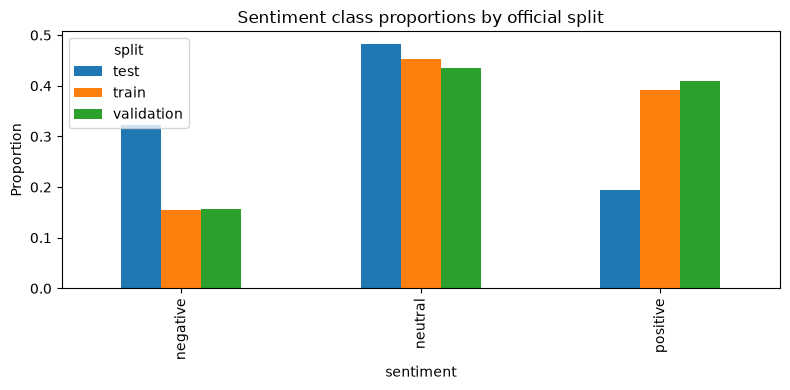

,tweet character count
count,45615.000000
mean,106.932851
std,26.251517
min,10.000000
25%,89.000000
50%,113.000000
75%,128.000000
max,200.000000


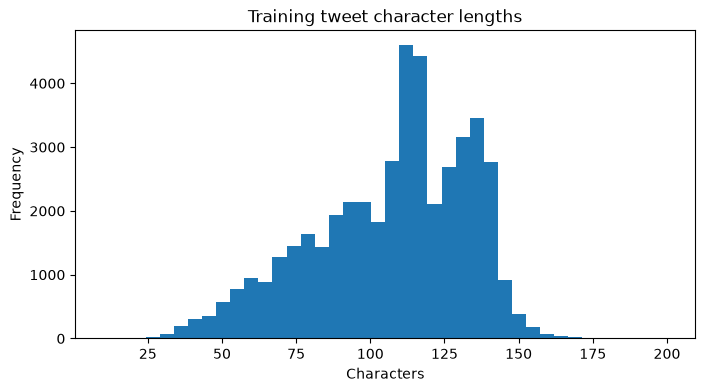

In [4]:
_write_eda(splits, ARTIFACTS)
class_counts = pd.DataFrame(summary)
class_counts.pivot(index="sentiment", columns="split", values="proportion").plot(kind="bar", figsize=(8, 4))
plt.title("Sentiment class proportions by official split")
plt.ylabel("Proportion")
plt.tight_layout()
plt.show()
text_lengths = pd.Series([len(text) for text in train_texts])
display(text_lengths.describe().to_frame("tweet character count"))
text_lengths.plot(kind="hist", bins=40, title="Training tweet character lengths", figsize=(8, 4))
plt.xlabel("Characters")
plt.show()

## 4. Data preprocessing and integrity checks

Integrity checks cover missing text, blank text, invalid sentiment labels, and exact duplicate `(text, label)` rows within each official partition. No missing or blank text and no invalid labels were found in the train, validation, or test splits. The training split contains 26 exact duplicate rows; validation and test contain none. The training duplicates remain in the data because the experiment preserves the benchmark files as distributed. Their presence can give repeated records additional influence during fitting, but within-split duplicate counts alone do not establish cross-split leakage.

No imputation is needed because the checked text and label fields are complete. Labels are retained in their original integer form and mapped to readable class names for tables and displays. Text is not manually rewritten, stripped of punctuation, or resampled. The TF-IDF pipeline applies the transformations required for modeling while preserving the benchmark examples and partition assignments.

In [5]:
integrity = []
for split_name, (texts, labels) in splits.items():
    frame = pd.DataFrame({"text": texts, "label": labels})
    integrity.append({
        "split": split_name,
        "rows": len(frame),
        "missing_text": int(frame["text"].isna().sum()),
        "blank_text": int(frame["text"].str.strip().eq("").sum()),
        "duplicate_rows_within_split": int(frame.duplicated().sum()),
        "invalid_labels": int((~frame["label"].isin([0, 1, 2])).sum()),
    })
display(pd.DataFrame(integrity))
assert all(row["missing_text"] == 0 and row["blank_text"] == 0 and row["invalid_labels"] == 0 for row in integrity)

,split,rows,missing_text,blank_text,duplicate_rows_within_split,invalid_labels
0,test,12284,0,0,0,0
1,train,45615,0,0,26,0
2,validation,2000,0,0,0,0


## 5. Feature engineering and feature interpretation

The sparse representation combines two TF-IDF feature spaces. The word analyzer lowercases text, applies Unicode accent normalization, represents unigrams and bigrams, ignores terms occurring fewer than twice in a fitting fold, and caps its vocabulary at 100,000 features. Sublinear term-frequency scaling limits the effect of repeated terms within one message. The character analyzer uses character n-grams of lengths three through five within word boundaries, a minimum document frequency of three, and a 100,000-feature cap. Word features represent terms and short phrases; character features can capture spelling variation, contractions, punctuation, and fragments of informal language.

Feature construction is contained inside the scikit-learn estimator pipeline. During cross-validation, every fold fits its own vocabulary and inverse-document-frequency weights using only that fold's training texts. The held-out fold therefore cannot affect the feature representation. After hyperparameter selection, the best pipeline is refitted on the full training partition; validation and test texts are transformed by that fitted pipeline without refitting the vocabulary. This prevents feature leakage from the evaluation partitions.

Linear-model coefficients provide a global description of features associated with class scores. These associations are not causal explanations and do not guarantee how a model interprets an individual tweet. Correlated n-grams can share weight, and a term can have different meanings in different contexts. The project exports coefficient-based feature summaries as aids for inspection rather than proof of human-like reasoning.

In [6]:
from sklearn.svm import LinearSVC
from src.model import make_pipeline

feature_demo = make_pipeline(LinearSVC(class_weight="balanced", random_state=42))
feature_demo.fit(train_texts[:5000], y_train[:5000])
matrix = feature_demo.named_steps["tfidf"].transform(train_texts[:3])
print("Example TF-IDF matrix shape:", matrix.shape)
print("Example learned features:", feature_demo.named_steps["tfidf"].get_feature_names_out()[:20])

Example TF-IDF matrix shape: (3, 46381)
Example learned features: ['word__00' 'word__00 30' 'word__00 am' 'word__000' 'word__000 for'
 'word__00am' 'word__00pm' 'word__01' 'word__02' 'word__03' 'word__04'
 'word__05' 'word__06' 'word__07' 'word__07 48' 'word__08' 'word__09'
 'word__10' 'word__10 10' 'word__10 30']


## 6. Dataset splitting and experimental design

The official 45,615/2,000/12,284 train/validation/test partitions are retained without random reassignment. Training data supports three-fold stratified cross-validation, hyperparameter search, and final refitting of each model family. The validation partition selects the model family by macro-F1 after configuration tuning. The test partition is reserved for final reporting and error analysis. This separation distinguishes parameter tuning, model selection, and final performance estimation.

Stratification is applied only when constructing cross-validation folds within the training split; it does not alter the official validation or test distributions. The three shuffled folds use a fixed random seed of 42. Because all folds come from the same training collection, cross-validation describes variation within this benchmark training distribution and does not measure robustness to future time periods, platforms, or source populations.

In [7]:
split_manifest = pd.DataFrame([
    {"split": name, "samples": len(texts), "class_counts": {LABELS[int(k)]: int(v) for k, v in pd.Series(labels).value_counts().items()}}
    for name, (texts, labels) in splits.items()
])
display(split_manifest)

,split,samples,class_counts
0,test,12284,"{'neutral': 5937, 'negative': 3972, 'positive'..."
1,train,45615,"{'neutral': 20673, 'positive': 17849, 'negativ..."
2,validation,2000,"{'neutral': 869, 'positive': 819, 'negative': ..."


## 7. Model selection

The majority baseline predicts the most frequent training class and establishes a reference for a classifier that does not use tweet text. Multinomial Naive Bayes is a probabilistic baseline suited to non-negative text features. Logistic Regression and Linear SVM learn discriminative linear decision boundaries in the high-dimensional sparse TF-IDF space; both use balanced class weights. Naive Bayes uses additive smoothing.

| Model | Hyperparameter search | Selection score |
|---|---|---|
| Majority baseline | Most frequent class; no tuned parameter | Three-fold training macro-F1 |
| Multinomial Naive Bayes | `alpha`: 0.1, 0.5, 1.0 | Three-fold training macro-F1 |
| Logistic Regression | `C`: 0.5, 1.0, 2.0; balanced class weights | Three-fold training macro-F1 |
| Linear SVM | `C`: 0.25, 0.5, 1.0; balanced class weights | Three-fold training macro-F1 |

For each family, grid search chooses the configuration with the highest mean macro-F1 across training folds and refits that estimator on all training examples. The separately held validation set then selects the family with the highest validation macro-F1. The test scores do not determine either the parameter settings or the selected family.

## 8. Model training and cross-validation

The model implementation uses `GridSearchCV` and a `StratifiedKFold` splitter with three folds, shuffling, and random seed 42. Each candidate configuration is scored by macro-F1. Since the feature union and classifier are fitted together in a pipeline, each fold independently learns word and character vocabularies from its training portion. The selected configurations are refitted on the complete 45,615-example training partition before evaluation on the official validation and test partitions.

The saved run gives Naive Bayes a best cross-validation macro-F1 of 0.6127 ± 0.0032 at `alpha=0.1`, Logistic Regression 0.6536 ± 0.0034 at `C=1.0`, and Linear SVM 0.6513 ± 0.0020 at `C=0.25`. Logistic Regression has the highest cross-validation mean, while Linear SVM has the highest validation macro-F1 (0.6765 compared with 0.6758). Linear SVM is consequently the selected model under the declared validation rule. The small validation difference indicates a close selection, not a decisive practical advantage.

In [8]:
from src.model import train

results = train()
print("Validation-selected model:", results["selected_model"])
print("Selection protocol:", results["selection_metric"])

Validation-selected model: linear_svm
Selection protocol: mean cross-validation macro-F1 tunes each model; validation macro-F1 selects the model family; test split is held out for final evaluation


In [9]:
cv_results = pd.read_csv(ARTIFACTS / "cross_validation_results.csv")
display(cv_results.sort_values(["model", "mean_macro_f1"], ascending=[True, False]))
split_metrics = pd.read_csv(ARTIFACTS / "metrics.csv")
display(split_metrics)

,model,params,mean_macro_f1,std_macro_f1,fold_0_macro_f1,fold_1_macro_f1,fold_2_macro_f1
7,linear_svm,"{""classifier__C"": 0.25}",0.651342,0.001954,0.653956,0.649259,0.650811
8,linear_svm,"{""classifier__C"": 0.5}",0.644028,0.000171,0.643848,0.643978,0.644258
9,linear_svm,"{""classifier__C"": 1.0}",0.633568,0.001618,0.635122,0.631337,0.634244
5,logistic_regression,"{""classifier__C"": 1.0}",0.653645,0.003431,0.658490,0.650993,0.651451
4,logistic_regression,"{""classifier__C"": 0.5}",0.652625,0.003865,0.658084,0.650127,0.649664
6,logistic_regression,"{""classifier__C"": 2.0}",0.650645,0.001861,0.653252,0.649646,0.649036
0,majority_baseline,{},0.207911,0.000000,0.207911,0.207911,0.207911
1,multinomial_nb,"{""classifier__alpha"": 0.1}",0.612740,0.003182,0.617062,0.611663,0.609495
2,multinomial_nb,"{""classifier__alpha"": 0.5}",0.532613,0.007567,0.543266,0.526419,0.528153
3,multinomial_nb,"{""classifier__alpha"": 1.0}",0.463254,0.004737,0.468799,0.457226,0.463737


,model,accuracy,macro_precision,macro_recall,macro_f1,test_accuracy,test_macro_precision,test_macro_recall,test_macro_f1
0,majority_baseline,0.4345,0.144833,0.333333,0.201929,0.483312,0.161104,0.333333,0.217222
1,multinomial_nb,0.6545,0.626034,0.635906,0.630115,0.604526,0.597211,0.608296,0.600988
2,logistic_regression,0.6975,0.667270,0.693851,0.675846,0.624552,0.615976,0.633614,0.622263
3,linear_svm,0.7045,0.673564,0.680117,0.676489,0.619098,0.608124,0.624090,0.614321


## 9. Model evaluation and error analysis

Accuracy is the fraction of all examples classified correctly. Precision is the fraction of predictions for a class that are correct; recall is the fraction of true examples of a class recovered by the model; F1 is the harmonic mean of precision and recall. Macro-averaging calculates each class score separately and averages the three values equally. This makes the reported macro metrics informative when class frequencies are uneven, while accuracy still describes the overall fraction correct.

The validation-selected Linear SVM obtains 0.6191 test accuracy, 0.6081 macro precision, 0.6241 macro recall, and 0.6143 macro-F1. Its per-class F1 values are 0.6084 for negative, 0.6351 for neutral, and 0.5995 for positive. Positive precision is 0.5510 and positive recall is 0.6573, indicating that positive examples are found more often than the precision score alone suggests, but that a notable number of non-positive posts also receive a positive prediction.

The paired bootstrap resamples identical test-example indices for the selected SVM and each alternative across 1,000 repetitions. The observed SVM-minus-Logistic macro-F1 difference is −0.0079, with a percentile 95% interval of approximately [−0.0126, −0.0032]. Logistic Regression therefore scores higher on this test sample. The interval is conditional on the benchmark test records and saved predictions; it does not account for temporal or domain shift and does not change the prior validation-based model selection.

In [10]:
test_report = json.loads((ARTIFACTS / "selected_model_test_report.json").read_text(encoding="utf-8"))
display(pd.DataFrame(test_report).T)
bootstrap = pd.read_csv(ARTIFACTS / "paired_bootstrap_macro_f1.csv")
display(bootstrap)
from IPython.display import Image, display as show_image
show_image(filename=str(ARTIFACTS / "confusion_matrix.png"))

,precision,recall,f1-score,support
negative,0.622269,0.595166,0.608416,3972.000000
neutral,0.651097,0.619842,0.635085,5937.000000
positive,0.551006,0.657263,0.599462,2375.000000
accuracy,0.619098,0.619098,0.619098,0.619098
macro avg,0.608124,0.624090,0.614321,12284.000000
weighted avg,0.622424,0.619098,0.619574,12284.000000


,comparison_model,selected_minus_comparison_macro_f1,paired_bootstrap_ci_2_5,paired_bootstrap_ci_97_5,repetitions,ci_excludes_zero
0,majority_baseline,0.397099,0.387660,0.406255,1000,True
1,multinomial_nb,0.013334,0.004924,0.021224,1000,True
2,logistic_regression,-0.007941,-0.012635,-0.003197,1000,True


In [11]:
demo_texts = [
    "I absolutely love this, it made my day!",
    "The product is okay, nothing special.",
    "Terrible service, I am very disappointed.",
]
demo = pd.DataFrame({"text": demo_texts, "prediction": [predict(text) for text in demo_texts]})
display(demo)

,text,prediction
0,"I absolutely love this, it made my day!",positive
1,"The product is okay, nothing special.",neutral
2,"Terrible service, I am very disappointed.",negative


## 10. Results, discussion, and conclusion

### Comparative performance

| Model | CV macro-F1 (mean ± SD) | Validation accuracy | Validation macro-F1 | Test accuracy | Test macro-F1 |
|---|---:|---:|---:|---:|---:|
| Majority baseline | 0.2079 ± 0.0000 | 0.4345 | 0.2019 | 0.4833 | 0.2172 |
| Multinomial Naive Bayes | 0.6127 ± 0.0032 | 0.6545 | 0.6301 | 0.6045 | 0.6010 |
| Logistic Regression | 0.6536 ± 0.0034 | 0.6975 | 0.6758 | 0.6246 | 0.6223 |
| Linear SVM (selected) | 0.6513 ± 0.0020 | 0.7045 | 0.6765 | 0.6191 | 0.6143 |

All three trained classifiers outperform the majority baseline on test macro-F1, showing that the text features contain predictive signal under the benchmark annotations. Linear SVM is retained as the final selected family because it narrowly leads validation macro-F1. Logistic Regression has the highest test accuracy and test macro-F1. Reporting this ranking difference transparently preserves the distinction between a prespecified validation decision and a final held-out comparison; changing the selected model after examining test results would turn the test set into a model-selection set.

The selected SVM's 61.9% test accuracy is substantially below the aspirational 80% target. Approximately 38% of its test predictions are incorrect. Cross-validation estimates performance across folds from the same training distribution and supports parameter selection; it cannot guarantee generalization or raise the score to a chosen target. The gap between validation and test performance occurs alongside a notable change in class proportions: negative examples rise from about 15.5% of training data to 32.3% of test data, while positive examples fall from about 39.1% to 19.3%. The shift is documented rather than corrected by resampling the official test set.

### Error interpretation and limitations

The n-gram representation captures useful word, phrase, and orthographic patterns but has limited ability to represent conversational context, word sense, irony, or sarcasm. A phrase such as “not bad” can contain a negative token while expressing approval; short posts may provide too little context to disambiguate intent. Character features support spelling variation but may also learn superficial associations. The confusion matrix identifies the direction of errors but cannot establish their linguistic causes. A systematic human-coded error study would be needed to assign causes reliably.

Further limitations include the age and provenance of the source posts, benchmark-specific annotation choices, retained duplicate training rows, class-distribution differences between official partitions, uncertain dataset license metadata, and possible changes in language over time. The results do not demonstrate current-year performance, fairness across dialects, or fitness for high-impact uses. TweetEval's 2020 release falls within the nominal benchmark window, but its underlying sentiment examples originate from SemEval 2017; acceptance under the course's exact recency interpretation remains a course-level decision. Exact split equivalence for later literature is not assumed unless confirmed from each study's methods.

The local dashboard demonstrates data browsing, metric visualization, confusion-matrix inspection, and text prediction using the saved pipeline. The three illustrative predictions in the preceding output test the inference path only; they are not a representative accuracy estimate. The application is an educational local prototype without production monitoring, authentication, calibration, or a human-review workflow. Any use beyond exploratory aggregation would require governance, data-term review, external validation, and a human decision process.

The project completes the benchmark comparison and prototype objectives: it preserves the official splits, checks data quality, performs leakage-conscious feature construction, tunes three classical model families, reports a majority baseline, evaluates the held-out test set, and exposes the resulting model through a dashboard. It does not achieve 80% accuracy or establish generalization to contemporary social-media populations. Potential future studies include an independently collected temporal test, a documented lexicon baseline, systematic human annotation of error samples, or evaluation of a properly licensed social-media language model with training-data overlap checks. These are proposals, not completed results.

### References

[1] F. Barbieri, J. Camacho-Collados, L. Espinosa Anke, and L. Neves, “TweetEval: Unified benchmark and comparative evaluation for tweet classification,” *Findings of EMNLP*, 2020. [doi:10.18653/v1/2020.findings-emnlp.148](https://doi.org/10.18653/v1/2020.findings-emnlp.148).  
[2] Cardiff NLP, “TweetEval dataset card: sentiment configuration.” [Hugging Face](https://huggingface.co/datasets/cardiffnlp/tweet_eval).  
[3] S. Rosenthal, N. Farra, and P. Nakov, “SemEval-2017 task 4: Sentiment analysis in Twitter,” *Proceedings of SemEval*, 2017. [doi:10.18653/v1/S17-2088](https://doi.org/10.18653/v1/S17-2088).  
[4] Cardiff NLP, “TweetEval: Unified benchmark and comparative evaluation for tweet classification.” [Official repository](https://github.com/cardiffnlp/tweeteval).  
[5] D. Loureiro et al., “TimeLMs: Diachronic language models from Twitter,” *ACL System Demonstrations*, 2022. [doi:10.18653/v1/2022.acl-demo.25](https://doi.org/10.18653/v1/2022.acl-demo.25).  
[6] F. Barbieri, L. Espinosa Anke, and J. Camacho-Collados, “XLM-T: Multilingual language models in Twitter for sentiment analysis and beyond,” *LREC*, 2022. [ACL Anthology](https://aclanthology.org/2022.lrec-1.27/).  
[7] B. Pang and L. Lee, “Opinion mining and sentiment analysis,” *Foundations and Trends in Information Retrieval*, vol. 2, nos. 1–2, pp. 1–135, 2008. [doi:10.1561/1500000011](https://doi.org/10.1561/1500000011).  
[8] B. Pang, L. Lee, and S. Vaithyanathan, “Thumbs up? Sentiment classification using machine learning techniques,” *EMNLP*, 2002. [doi:10.3115/1118693.1118704](https://doi.org/10.3115/1118693.1118704).  
[9] C. Hutto and E. Gilbert, “VADER: A parsimonious rule-based model for sentiment analysis of social media text,” *ICWSM*, vol. 8, no. 1, pp. 216–225, 2014. [doi:10.1609/icwsm.v8i1.14550](https://doi.org/10.1609/icwsm.v8i1.14550).  
[10] J. Huang and R. Usbeck, “Revisiting supervised contrastive learning for microblog classification,” *EMNLP*, 2024. [doi:10.18653/v1/2024.emnlp-main.876](https://doi.org/10.18653/v1/2024.emnlp-main.876).  
[11] D. Q. Nguyen, T. Vu, and A. T. Nguyen, “BERTweet: A pre-trained language model for English tweets,” *EMNLP System Demonstrations*, 2020. [doi:10.18653/v1/2020.emnlp-demos.2](https://doi.org/10.18653/v1/2020.emnlp-demos.2).  
[12] M. Sokolova and G. Lapalme, “A systematic analysis of performance measures for classification tasks,” *Information Processing & Management*, vol. 45, no. 4, pp. 427–437, 2009. [doi:10.1016/j.ipm.2009.03.002](https://doi.org/10.1016/j.ipm.2009.03.002).  
[13] M. T. Ribeiro, S. Singh, and C. Guestrin, “‘Why should I trust you?’: Explaining the predictions of any classifier,” *KDD*, 2016. [doi:10.1145/2939672.2939778](https://doi.org/10.1145/2939672.2939778).

### AI-use disclosure

AI-assisted drafting and editing support was used in preparing this notebook and related project materials. The student remains responsible for verifying the code, results, sources, and dataset terms, understanding the analysis, revising the work in their own understanding, and completing the institution's required AI-use declaration accurately.